# DSA 2050 — Week 6 Guided Practical Lab: Regression and Baseline Comparison

**Student:** Dancan Ratemo  
**Student ID:** 666172  
**Dataset:** `DSA2050_Week6_Sales_Data.csv`  
**Reproducibility:** `RANDOM_STATE = 42`

## Objective
Estimate sales (KES) from advertising spend, store visits, discount, region, customer segment, and product category. Compare constant-prediction baselines with linear regression, Ridge regression, and a shallow decision tree. The final test set is held out from all model selection; preprocessing and cross-validation are performed within training data.

## 1. Imports and reproducibility

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Load the dataset and define the task
Each row represents one business sales observation. The target is `Sales_KES`; the six remaining columns are the predictors described in the guide.

In [2]:
df = pd.read_csv("DSA2050_Week6_Sales_Data.csv")
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")
display(df.head())
df.info()

Shape: 320 rows × 7 columns


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
0,10801,326,17,Nairobi,SME,Electronics,152376
1,55307,162,23,Nairobi,Retail,Home,119137
2,47547,553,22,Mombasa,Corporate,Office,219441
3,33527,785,12,Nairobi,SME,Electronics,234210
4,33145,830,20,Nairobi,Retail,Home,204277


<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   AdvertisingSpend_KES  320 non-null    int64
 1   StoreVisits           320 non-null    int64
 2   DiscountPercent       320 non-null    int64
 3   Region                320 non-null    str  
 4   CustomerSegment       320 non-null    str  
 5   ProductCategory       320 non-null    str  
 6   Sales_KES             320 non-null    int64
dtypes: int64(4), str(3)
memory usage: 17.6 KB


In [3]:
target = "Sales_KES"
numeric_features = ["AdvertisingSpend_KES", "StoreVisits", "DiscountPercent"]
categorical_features = ["Region", "CustomerSegment", "ProductCategory"]
print("Numeric predictors:", numeric_features)
print("Categorical predictors:", categorical_features)
print("Target:", target)
print(f"\nThere are {df.shape[0]} observations and {df.shape[1]} columns. Each row is a sales case; the prediction target is Sales_KES.")

Numeric predictors: ['AdvertisingSpend_KES', 'StoreVisits', 'DiscountPercent']
Categorical predictors: ['Region', 'CustomerSegment', 'ProductCategory']
Target: Sales_KES

There are 320 observations and 7 columns. Each row is a sales case; the prediction target is Sales_KES.


## 3. Basic data audit

In [4]:
print("Missing values by column:")
display(df.isna().sum().to_frame("Missing"))
print("Duplicate rows:", df.duplicated().sum())
display(df.describe(include="all"))
display(df[target].describe().to_frame("Sales_KES"))

Missing values by column:


,Missing
AdvertisingSpend_KES,0
StoreVisits,0
DiscountPercent,0
Region,0
CustomerSegment,0
ProductCategory,0
Sales_KES,0


Duplicate rows: 0


,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,Sales_KES
count,320.00,320.00,320.00,320,320,320,320.00
unique,NaN,NaN,NaN,4,3,4,NaN
top,NaN,NaN,NaN,Nairobi,Retail,Electronics,NaN
freq,NaN,NaN,NaN,139,157,95,NaN
mean,"37,421.78",465.44,12.81,NaN,NaN,NaN,"169,252.45"
std,"17,745.83",231.65,7.72,NaN,NaN,NaN,"51,968.08"
min,"5,478.00",84.00,0.00,NaN,NaN,NaN,"17,805.00"
25%,"22,985.50",262.00,6.00,NaN,NaN,NaN,"131,448.75"
50%,"37,144.00",461.50,13.50,NaN,NaN,NaN,"168,462.00"
75%,"52,307.75",685.50,20.00,NaN,NaN,NaN,"207,050.75"


,Sales_KES
count,320.00
mean,"169,252.45"
std,"51,968.08"
min,"17,805.00"
25%,"131,448.75"
50%,"168,462.00"
75%,"207,050.75"
max,"295,825.00"


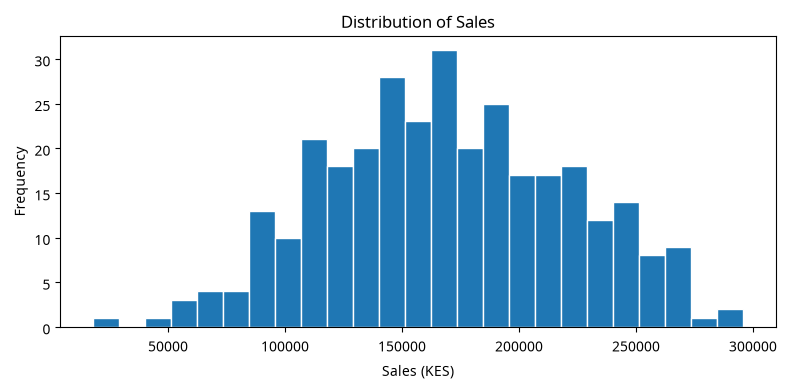

Sales ranges from KES 17,805 to KES 295,825; median is KES 168,462. The mean is KES 169,252.
Inspect the histogram and quartiles before treating extreme observations as errors; high or low sales may be genuine business cases.


In [5]:
plt.figure(figsize=(8, 4))
plt.hist(df[target], bins=25, edgecolor="white")
plt.title("Distribution of Sales")
plt.xlabel("Sales (KES)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
print(f"Sales ranges from KES {df[target].min():,.0f} to KES {df[target].max():,.0f}; median is KES {df[target].median():,.0f}. The mean is KES {df[target].mean():,.0f}.")
print("Inspect the histogram and quartiles before treating extreme observations as errors; high or low sales may be genuine business cases.")

## 4. Features, target, and untouched holdout

In [6]:
X = df.drop(columns=target)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("X shape:", X.shape, "| y shape:", y.shape)

Training rows: 256 | Test rows: 64
X shape: (320, 6) | y shape: (320,)


## 5. Leakage-safe preprocessing
Imputers, scaling, and one-hot encoding are inside a `ColumnTransformer` that itself lives inside each model pipeline. Consequently, when a pipeline is cross-validated, each fold learns preprocessing only from that fold’s training partition. Scaling is useful for the linear/Ridge models; it does not leak because it is fitted within the pipeline.

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

## 6. Evaluation helper and constant baselines

In [8]:
def evaluate_regression(y_true, y_pred, name):
    return {"Model": name,
            "MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

mean_baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
median_baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
mean_pred = mean_baseline.predict(X_test)
median_pred = median_baseline.predict(X_test)
results = [evaluate_regression(y_test, mean_pred, "Mean Baseline"),
           evaluate_regression(y_test, median_pred, "Median Baseline")]
display(pd.DataFrame(results).set_index("Model"))
print(f"The training-set mean is KES {y_train.mean():,.2f}; the training-set median is KES {y_train.median():,.2f}.")

,MAE,RMSE,R2
Model,,,
Mean Baseline,"39,197.16","48,716.43",-0.01
Median Baseline,"39,146.75","48,649.47",-0.01


The training-set mean is KES 170,141.51; the training-set median is KES 169,335.00.


## 7. Linear regression, Ridge, and shallow decision tree

In [9]:
linear_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
ridge_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", Ridge(alpha=1.0))
])
tree_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(max_depth=4, min_samples_leaf=8,
                                     random_state=RANDOM_STATE))
])
models = {"Linear Regression": linear_model,
          "Ridge Regression": ridge_model,
          "Decision Tree": tree_model}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    results.append(evaluate_regression(y_test, predictions[name], name))
comparison = pd.DataFrame(results).sort_values("MAE").reset_index(drop=True)
display(comparison)

,Model,MAE,RMSE,R2
0,Ridge Regression,"13,714.40","17,458.82",0.87
1,Linear Regression,"13,757.84","17,469.69",0.87
2,Decision Tree,"23,775.92","28,767.64",0.65
3,Median Baseline,"39,146.75","48,649.47",-0.01
4,Mean Baseline,"39,197.16","48,716.43",-0.01


### Metric interpretation
- **MAE** is the average absolute miss in KES and is directly interpretable as typical error magnitude; lower is better.
- **RMSE** is also in KES but penalizes large errors more heavily; lower is better.
- **R²** compares error to the test target’s variation; larger is generally better, and negative R² means worse squared-error performance than predicting the test mean.

The following prints identify each metric leader and compare the best candidate with both baselines.

In [10]:
best_mae_row = comparison.loc[comparison["Model"].isin(models)].sort_values("MAE").iloc[0]
best_rmse_row = comparison.loc[comparison["Model"].isin(models)].sort_values("RMSE").iloc[0]
best_r2_row = comparison.loc[comparison["Model"].isin(models)].sort_values("R2", ascending=False).iloc[0]
strongest_baseline = comparison.loc[comparison["Model"].isin(["Mean Baseline", "Median Baseline"])].sort_values("MAE").iloc[0]
print(f"Lowest candidate MAE: {best_mae_row['Model']} (KES {best_mae_row['MAE']:,.2f})")
print(f"Lowest candidate RMSE: {best_rmse_row['Model']} (KES {best_rmse_row['RMSE']:,.2f})")
print(f"Highest candidate R²: {best_r2_row['Model']} ({best_r2_row['R2']:.3f})")
print(f"Strongest baseline by MAE: {strongest_baseline['Model']} (KES {strongest_baseline['MAE']:,.2f})")
print(f"Best candidate MAE improvement vs strongest baseline: KES {strongest_baseline['MAE']-best_mae_row['MAE']:,.2f} ({(strongest_baseline['MAE']-best_mae_row['MAE'])/strongest_baseline['MAE']*100:.1f}%).")
print("A single test split is uncertain: cross-validation, residual/subgroup checks, data representativeness, and future validation are needed before choosing a deployable model.")

Lowest candidate MAE: Ridge Regression (KES 13,714.40)
Lowest candidate RMSE: Ridge Regression (KES 17,458.82)
Highest candidate R²: Ridge Regression (0.870)
Strongest baseline by MAE: Median Baseline (KES 39,146.75)
Best candidate MAE improvement vs strongest baseline: KES 25,432.35 (65.0%).
A single test split is uncertain: cross-validation, residual/subgroup checks, data representativeness, and future validation are needed before choosing a deployable model.


## 8. Training-only cross-validation
Five-fold CV below uses only the training data. The sign of scikit-learn’s negative error scorers is reversed to report positive MAE/RMSE. The holdout test set is not used to tune these models.

In [11]:
scoring = {"MAE": "neg_mean_absolute_error",
           "RMSE": "neg_root_mean_squared_error",
           "R2": "r2"}
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({"Model": name,
                    "CV_MAE": -scores["test_MAE"].mean(),
                    "CV_MAE_SD": scores["test_MAE"].std(),
                    "CV_RMSE": -scores["test_RMSE"].mean(),
                    "CV_R2": scores["test_R2"].mean()})
cv_results = pd.DataFrame(cv_rows).sort_values("CV_MAE").reset_index(drop=True)
display(cv_results)
cv_winner = cv_results.iloc[0]
test_candidate_winner = comparison[comparison["Model"].isin(models)].sort_values("MAE").iloc[0]
print(f"Best average CV MAE: {cv_winner['Model']} (KES {cv_winner['CV_MAE']:,.2f} ± {cv_winner['CV_MAE_SD']:,.2f}).")
print(f"Test MAE winner: {test_candidate_winner['Model']}. CV and test winner {'agree' if cv_winner['Model'] == test_candidate_winner['Model'] else 'differ'}, so the selected ranking is {'consistent' if cv_winner['Model'] == test_candidate_winner['Model'] else 'not fully consistent'} across these estimates.")
print("Training-only CV supports model development without repeatedly adapting to the final test set, which would make that test estimate optimistically biased.")

,Model,CV_MAE,CV_MAE_SD,CV_RMSE,CV_R2
0,Ridge Regression,"16,049.72","1,315.68","20,240.98",0.85
1,Linear Regression,"16,062.74","1,293.28","20,254.00",0.85
2,Decision Tree,"23,647.67","3,502.30","28,958.04",0.69


Best average CV MAE: Ridge Regression (KES 16,049.72 ± 1,315.68).
Test MAE winner: Ridge Regression. CV and test winner agree, so the selected ranking is consistent across these estimates.
Training-only CV supports model development without repeatedly adapting to the final test set, which would make that test estimate optimistically biased.


## 9. Residual analysis for Linear Regression
Residual = actual − predicted. Positive means under-prediction; negative means over-prediction.

,Actual,Predicted,Residual
0,149359,"136,532.31","12,826.69"
1,198924,"196,021.09","2,902.91"
2,152671,"143,638.94","9,032.06"
3,133621,"172,495.44","-38,874.44"
4,171171,"149,069.70","22,101.30"


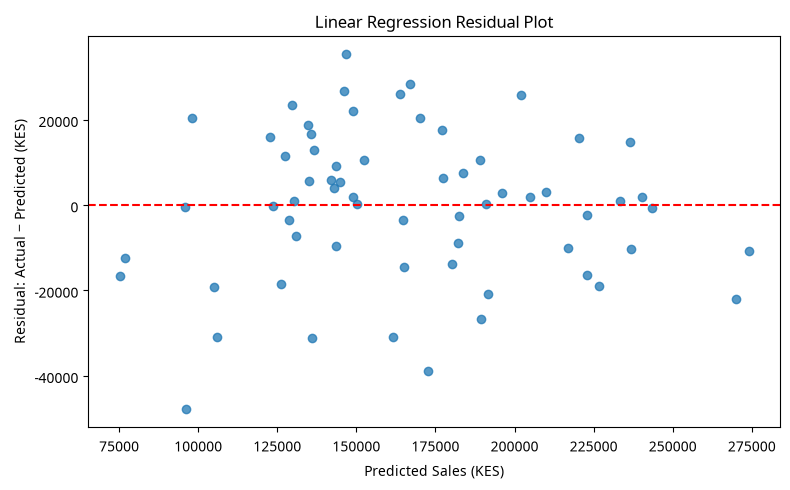

Mean residual: KES -337.25; median: KES 976.95; largest absolute residual: KES 47,859.85.
Assess whether residuals are centered around zero and whether their spread or sign changes across predictions. Structure suggests model misspecification; unusually large residuals warrant case-level review rather than automatic deletion.


In [12]:
linear_pred = predictions["Linear Regression"]
residuals = y_test.to_numpy() - linear_pred
residual_df = pd.DataFrame({"Actual": y_test.to_numpy(),
                            "Predicted": linear_pred,
                            "Residual": residuals})
display(residual_df.head())
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(linear_pred, residuals, alpha=.75)
ax.axhline(0, color="red", linestyle="--")
ax.set(title="Linear Regression Residual Plot", xlabel="Predicted Sales (KES)", ylabel="Residual: Actual − Predicted (KES)")
plt.tight_layout(); plt.show()
print(f"Mean residual: KES {residuals.mean():,.2f}; median: KES {np.median(residuals):,.2f}; largest absolute residual: KES {np.abs(residuals).max():,.2f}.")
print("Assess whether residuals are centered around zero and whether their spread or sign changes across predictions. Structure suggests model misspecification; unusually large residuals warrant case-level review rather than automatic deletion.")

## 10. Actual versus predicted

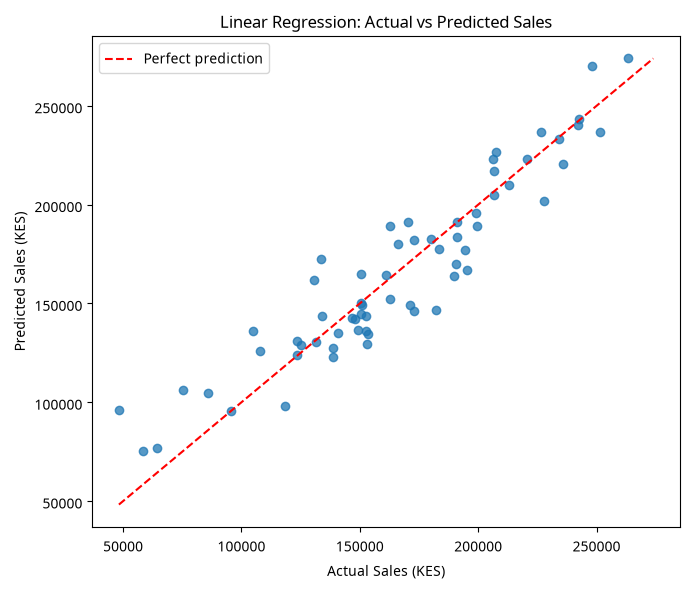

In [13]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, linear_pred, alpha=.75)
lo = min(y_test.min(), linear_pred.min()); hi = max(y_test.max(), linear_pred.max())
plt.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
plt.title("Linear Regression: Actual vs Predicted Sales")
plt.xlabel("Actual Sales (KES)"); plt.ylabel("Predicted Sales (KES)"); plt.legend()
plt.tight_layout(); plt.show()

## 11. Largest errors and customer-segment performance

In [14]:
error_analysis = X_test.copy()
error_analysis["ActualSales"] = y_test
error_analysis["PredictedSales"] = linear_pred
error_analysis["Residual"] = error_analysis["ActualSales"] - error_analysis["PredictedSales"]
error_analysis["AbsoluteError"] = error_analysis["Residual"].abs()
display(error_analysis.sort_values("AbsoluteError", ascending=False).head(10))
segment_errors = (error_analysis.groupby("CustomerSegment")
                  .agg(Observations=("AbsoluteError", "size"),
                       MAE=("AbsoluteError", "mean"))
                  .sort_values("MAE", ascending=False).reset_index())
display(segment_errors)
highest_segment = segment_errors.iloc[0]
print(f"Highest segment MAE: {highest_segment['CustomerSegment']} (KES {highest_segment['MAE']:,.2f}; n={highest_segment['Observations']}).")
print(f"Segment sample sizes range from {segment_errors['Observations'].min()} to {segment_errors['Observations'].max()} test cases.")
print("Largest misses should be checked for common regions, segments, categories, or predictor ranges. Segment error differences can reveal unequal model quality that aggregate MAE hides; small subgroup counts make estimates uncertain.")
print("Potential useful additional data: season/date, location/store, inventory and availability, price and product mix, competitor activity, campaign timing, and historical sales.")

,AdvertisingSpend_KES,StoreVisits,DiscountPercent,Region,CustomerSegment,ProductCategory,ActualSales,PredictedSales,Residual,AbsoluteError
139,33386,161,22,Nairobi,Retail,Home,48229,"96,088.85","-47,859.85","47,859.85"
63,67888,265,4,Nakuru,SME,Accessories,133621,"172,495.44","-38,874.44","38,874.44"
46,33969,441,10,Nakuru,Retail,Accessories,182186,"146,807.12","35,378.88","35,378.88"
7,50328,108,13,Nairobi,Retail,Electronics,104994,"136,091.95","-31,097.95","31,097.95"
5,60808,257,8,Nairobi,Retail,Accessories,130757,"161,701.20","-30,944.20","30,944.20"
76,26462,114,13,Nairobi,Retail,Electronics,75103,"106,000.27","-30,897.27","30,897.27"
260,56576,151,0,Nairobi,Corporate,Home,195145,"166,919.22","28,225.78","28,225.78"
226,57562,410,21,Kisumu,Corporate,Office,162770,"189,424.02","-26,654.02","26,654.02"
73,13444,541,19,Nakuru,Retail,Electronics,172866,"146,216.70","26,649.30","26,649.30"
297,33529,285,3,Nairobi,Corporate,Office,189884,"163,816.77","26,067.23","26,067.23"


,CustomerSegment,Observations,MAE
0,Retail,27,"15,560.58"
1,Corporate,19,"14,300.00"
2,SME,18,"10,481.46"


Highest segment MAE: Retail (KES 15,560.58; n=27).
Segment sample sizes range from 18 to 27 test cases.
Largest misses should be checked for common regions, segments, categories, or predictor ranges. Segment error differences can reveal unequal model quality that aggregate MAE hides; small subgroup counts make estimates uncertain.
Potential useful additional data: season/date, location/store, inventory and availability, price and product mix, competitor activity, campaign timing, and historical sales.


## 12. Overfitting check

In [15]:
tree_train_pred = tree_model.predict(X_train)
shallow_train_mae = mean_absolute_error(y_train, tree_train_pred)
shallow_test_mae = mean_absolute_error(y_test, predictions["Decision Tree"])
print(f"Shallow tree training MAE: KES {shallow_train_mae:,.2f}")
print(f"Shallow tree test MAE: KES {shallow_test_mae:,.2f}")
deep_tree = Pipeline([
    ("preprocess", preprocessor),
    ("model", DecisionTreeRegressor(random_state=RANDOM_STATE))
])
deep_tree.fit(X_train, y_train)
deep_train_pred = deep_tree.predict(X_train)
deep_test_pred = deep_tree.predict(X_test)
deep_train_mae = mean_absolute_error(y_train, deep_train_pred)
deep_test_mae = mean_absolute_error(y_test, deep_test_pred)
print(f"Deep tree training MAE: KES {deep_train_mae:,.2f}")
print(f"Deep tree test MAE: KES {deep_test_mae:,.2f}")
print("A near-perfect training score for an unrestricted tree indicates it can memorize training observations. Generalization must be judged on held-out/CV data; a large train–test gap is overfitting evidence.")

Shallow tree training MAE: KES 18,029.70
Shallow tree test MAE: KES 23,775.92
Deep tree training MAE: KES 0.00
Deep tree test MAE: KES 26,797.50
A near-perfect training score for an unrestricted tree indicates it can memorize training observations. Generalization must be judged on held-out/CV data; a large train–test gap is overfitting evidence.


## 13. Extension challenge — Ridge regularization strength
Compare α = 0.1, 1, 10, and 100 using five-fold CV on training data to select the regularization strength; then show each selected pipeline’s held-out test MAE once. The test values are diagnostic, not a tuning criterion.

In [16]:
alpha_values = [0.1, 1, 10, 100]
alpha_rows = []
for alpha in alpha_values:
    candidate = Pipeline([
        ("preprocess", preprocessor),
        ("model", Ridge(alpha=alpha))
    ])
    scores = cross_validate(candidate, X_train, y_train, cv=cv,
                            scoring="neg_mean_absolute_error")
    candidate.fit(X_train, y_train)
    alpha_rows.append({"alpha": alpha,
                       "CV_MAE": -scores["test_score"].mean(),
                       "Test_MAE": mean_absolute_error(y_test, candidate.predict(X_test))})
ridge_alpha_results = pd.DataFrame(alpha_rows).sort_values("CV_MAE")
display(ridge_alpha_results)
best_alpha = ridge_alpha_results.iloc[0]
print(f"Lowest CV MAE among tested alphas: alpha={best_alpha['alpha']}, CV MAE KES {best_alpha['CV_MAE']:,.2f}; corresponding test MAE KES {best_alpha['Test_MAE']:,.2f}.")

,alpha,CV_MAE,Test_MAE
1,1.00,"16,049.72","13,714.40"
0,0.10,"16,061.05","13,753.36"
2,10.00,"16,143.90","13,624.90"
3,100.00,"21,836.79","16,922.75"


Lowest CV MAE among tested alphas: alpha=1.0, CV MAE KES 16,049.72; corresponding test MAE KES 13,714.40.


## 14. Final recommendation
The paragraph below is generated from the observed results; review the diagnostic plots and tables alongside it.

In [17]:
mean_row = comparison[comparison.Model == "Mean Baseline"].iloc[0]
median_row = comparison[comparison.Model == "Median Baseline"].iloc[0]
best = best_mae_row
seg_sentence = f"The largest customer-segment MAE is for {highest_segment['CustomerSegment']} (KES {highest_segment['MAE']:,.0f}; n={highest_segment['Observations']}), so segment-level monitoring is warranted."
gap = deep_test_mae - deep_train_mae
overfit_sentence = (f"The unrestricted tree shows a large train–test MAE gap of KES {gap:,.0f}, consistent with overfitting." if gap > 0.1 * deep_test_mae else f"The unrestricted tree's train–test MAE gap is KES {gap:,.0f}; it should still be evaluated using out-of-sample validation.")
print(f"The stronger constant baseline by test MAE is the {strongest_baseline['Model'].lower()}, with MAE KES {strongest_baseline['MAE']:,.0f}. Among the three prespecified candidate models, {best['Model']} has the lowest test MAE (KES {best['MAE']:,.0f}); its RMSE is KES {best_rmse_row['RMSE']:,.0f} and R² is {best_r2_row['R2']:.3f} for the respective metric leaders. It {'does' if best['MAE'] < strongest_baseline['MAE'] else 'does not'} beat the stronger baseline on MAE on this one holdout split. An MAE of KES {best['MAE']:,.0f} means the average absolute prediction error is about that many shillings per observation, not that every estimate is wrong by that amount. Linear-model residuals have mean KES {residuals.mean():,.0f} and largest absolute error KES {np.abs(residuals).max():,.0f}; inspect the residual plot for patterns and investigate the largest cases. {seg_sentence} {overfit_sentence} I would not deploy immediately: validate on later-period data, investigate high-impact errors and segment fairness, confirm the data represent real operating conditions, and establish monitoring before any business use.")

The stronger constant baseline by test MAE is the median baseline, with MAE KES 39,147. Among the three prespecified candidate models, Ridge Regression has the lowest test MAE (KES 13,714); its RMSE is KES 17,459 and R² is 0.870 for the respective metric leaders. It does beat the stronger baseline on MAE on this one holdout split. An MAE of KES 13,714 means the average absolute prediction error is about that many shillings per observation, not that every estimate is wrong by that amount. Linear-model residuals have mean KES -337 and largest absolute error KES 47,860; inspect the residual plot for patterns and investigate the largest cases. The largest customer-segment MAE is for Retail (KES 15,561; n=27), so segment-level monitoring is warranted. The unrestricted tree shows a large train–test MAE gap of KES 26,798, consistent with overfitting. I would not deploy immediately: validate on later-period data, investigate high-impact errors and segment fairness, confirm the data represent r

## 15. Limitations

1. This is a single dataset with 320 rows and may be a teaching or synthetic sample; its findings may not generalize to operating stores or future periods.
2. The predictors are limited and omit potentially important influences such as seasonality, store-level context, product price/mix, inventory constraints, and competitor activity.
3. A random holdout split does not test temporal drift or future-period performance; no external validation dataset is available.
4. Prediction is not causation: associations between advertising, discounts, visits, and sales do not establish the effect of changing those inputs.
5. Subgroup metrics are based on relatively small test samples, so segment rankings are uncertain and should be interpreted cautiously.

## Reproducibility and submission checklist
- Run all cells from top to bottom after restarting the kernel.
- Keep the CSV beside this notebook.
- Replace the student name and ID in the opening section and README.
- This notebook uses one untouched 20% test split and training-only CV; do not use holdout test metrics to repeatedly tune models.
- Save the executed notebook with outputs before submitting.